<a href="https://colab.research.google.com/github/camsmugereski/BU-OMDS-Capstone/blob/main/OMDS_ModC1_Week4_Smugereski_Cameron.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 4 Jupyter Notebook – Logistic Regression and Feature Scaling
## Predicting Loan Default

### Project Overview

For Week 4, I am continuing to use the Credit Risk dataset from my capstone project. Since logistic regression is used for classification instead of predicting a continuous value, I changed the target variable from `loan_amnt` to `loan_status`.

For this analysis, I am using logistic regression to predict whether a borrower defaults on a loan. This also gives me a chance to look at the dataset from a different perspective than I did in Weeks 1 through 3.

I will compare logistic regression before and after feature scaling to see how scaling affects the model and its performance.

The main question I am looking at is:

**How well can borrower and loan characteristics predict loan default, and how does feature scaling affect logistic regression performance?**

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from google.colab import files

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    classification_report
)

pd.set_option('display.max_columns', None)

In [ ]:
uploaded = files.upload()

file_name = list(uploaded.keys())[0]

df = pd.read_csv(file_name)

print("File loaded:", file_name)
print("Dataset shape:", df.shape)

df.head()

Saving credit_risk_dataset 2.csv to credit_risk_dataset 2.csv
File loaded: credit_risk_dataset 2.csv
Dataset shape: (32581, 12)


,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4


In [ ]:
print("Loan Status Counts:")
print(df['loan_status'].value_counts())

print("\nLoan Status Percentages:")
print(
    df['loan_status']
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

Loan Status Counts:
loan_status
0    25473
1     7108
Name: count, dtype: int64

Loan Status Percentages:
loan_status
0    78.18
1    21.82
Name: proportion, dtype: float64


## Target Variable

For this analysis, I am using `loan_status` as the target variable. This changes the Week 4 analysis from a regression problem to a classification problem.

Before building the model, I looked at the number and percentage of observations in each class. This is important because if one class is much more common than the other, accuracy by itself may not give a complete picture of how well the model is performing.

Because the goal is to identify loan defaults, I will look at precision, recall, F1 score, and ROC-AUC in addition to overall accuracy.

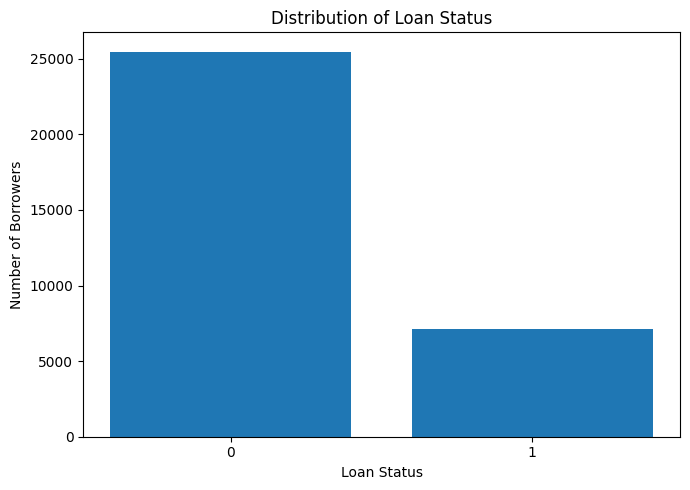

In [ ]:
class_counts = df['loan_status'].value_counts().sort_index()

plt.figure(figsize=(7, 5))

plt.bar(
    class_counts.index.astype(str),
    class_counts.values
)

plt.xlabel('Loan Status')
plt.ylabel('Number of Borrowers')
plt.title('Distribution of Loan Status')

plt.tight_layout()
plt.show()

In [ ]:
target = 'loan_status'

continuous_features = [
    'person_age',
    'person_income',
    'person_emp_length',
    'loan_amnt',
    'loan_int_rate',
    'loan_percent_income',
    'cb_person_cred_hist_length'
]

categorical_features = [
    'person_home_ownership',
    'loan_intent',
    'loan_grade',
    'cb_person_default_on_file'
]

model_columns = (
    continuous_features +
    categorical_features +
    [target]
)

data = df[model_columns].copy()

print(
    "Rows before removing missing values:",
    len(data)
)

data = data.dropna()

print(
    "Rows after removing missing values:",
    len(data)
)

data.head()

Rows before removing missing values: 32581
Rows after removing missing values: 28638


,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_percent_income,cb_person_cred_hist_length,person_home_ownership,loan_intent,loan_grade,cb_person_default_on_file,loan_status
0,22,59000,123.0,35000,16.02,0.59,3,RENT,PERSONAL,D,Y,1
1,21,9600,5.0,1000,11.14,0.10,2,OWN,EDUCATION,B,N,0
2,25,9600,1.0,5500,12.87,0.57,3,MORTGAGE,MEDICAL,C,N,1
3,23,65500,4.0,35000,15.23,0.53,2,RENT,MEDICAL,C,N,1
4,24,54400,8.0,35000,14.27,0.55,4,RENT,MEDICAL,C,Y,1


## Predictor Variables

I am using a mix of continuous and categorical borrower and loan characteristics as predictors.

Unlike Weeks 2 and 3, I included `loan_percent_income` again. Previously, I removed this variable because I was trying to predict `loan_amnt`, and loan percent income is calculated using loan amount. That created a target leakage concern.

For Week 4, the target is now `loan_status`, so that same issue does not apply. Loan percent income may actually be useful for predicting default because it shows how large a borrower's loan is compared with their income.

In [ ]:
X = data[
    continuous_features +
    categorical_features
]

y = data[target]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print(
    "Training observations:",
    len(X_train)
)

print(
    "Testing observations:",
    len(X_test)
)

print("\nTraining class distribution:")
print(
    y_train
    .value_counts(normalize=True)
    .round(4)
)

print("\nTesting class distribution:")
print(
    y_test
    .value_counts(normalize=True)
    .round(4)
)

Training observations: 22910
Testing observations: 5728

Training class distribution:
loan_status
0    0.7834
1    0.2166
Name: proportion, dtype: float64

Testing class distribution:
loan_status
0    0.7833
1    0.2167
Name: proportion, dtype: float64


## Train/Test Split

I split the data into 80% training data and 20% testing data.

I also used stratification based on `loan_status`. This keeps the percentage of defaults and non-defaults approximately the same in the training and testing datasets.

This is useful for classification because I do not want one dataset to randomly contain a much larger percentage of defaults than the other.

## Logistic Regression Without Feature Scaling

I first created a logistic regression model without scaling the continuous variables. This gives me a baseline that I can compare with the scaled model.

The categorical variables still need to be converted into dummy variables, but the continuous variables are left on their original scales.

In [ ]:
unscaled_preprocessor = ColumnTransformer(
    transformers=[
        (
            'continuous',
            'passthrough',
            continuous_features
        ),
        (
            'categorical',
            OneHotEncoder(
                drop='first',
                handle_unknown='ignore'
            ),
            categorical_features
        )
    ]
)

In [ ]:
unscaled_model = Pipeline(
    steps=[
        (
            'preprocessor',
            unscaled_preprocessor
        ),
        (
            'logistic',
            LogisticRegression(
                max_iter=5000,
                solver='liblinear'
            )
        )
    ]
)

unscaled_model.fit(
    X_train,
    y_train
)

unscaled_pred = unscaled_model.predict(
    X_test
)

unscaled_prob = unscaled_model.predict_proba(
    X_test
)[:, 1]

In [ ]:
unscaled_accuracy = accuracy_score(
    y_test,
    unscaled_pred
)

unscaled_precision = precision_score(
    y_test,
    unscaled_pred
)

unscaled_recall = recall_score(
    y_test,
    unscaled_pred
)

unscaled_f1 = f1_score(
    y_test,
    unscaled_pred
)

unscaled_auc = roc_auc_score(
    y_test,
    unscaled_prob
)

print("Unscaled Logistic Regression")
print("----------------------------")

print(
    f"Accuracy:  {unscaled_accuracy:.4f}"
)

print(
    f"Precision: {unscaled_precision:.4f}"
)

print(
    f"Recall:    {unscaled_recall:.4f}"
)

print(
    f"F1 Score:  {unscaled_f1:.4f}"
)

print(
    f"ROC-AUC:   {unscaled_auc:.4f}"
)

print("\nClassification Report:")

print(
    classification_report(
        y_test,
        unscaled_pred
    )
)

Unscaled Logistic Regression
----------------------------
Accuracy:  0.8032
Precision: 0.7007
Recall:    0.1604
F1 Score:  0.2610
ROC-AUC:   0.7520

Classification Report:
              precision    recall  f1-score   support

           0       0.81      0.98      0.89      4487
           1       0.70      0.16      0.26      1241

    accuracy                           0.80      5728
   macro avg       0.75      0.57      0.57      5728
weighted avg       0.79      0.80      0.75      5728



## Logistic Regression With Feature Scaling

Next, I standardized the continuous predictors before fitting the logistic regression model.

The continuous variables in this dataset are measured on very different scales. For example, income can be in the tens of thousands of dollars while loan percent income is represented as a decimal.

Standardizing the variables gives them a mean of approximately zero and a standard deviation of one. I want to see whether putting the continuous predictors on similar scales changes the performance of the logistic regression model.

In [ ]:
scaled_preprocessor = ColumnTransformer(
    transformers=[
        (
            'continuous',
            StandardScaler(),
            continuous_features
        ),
        (
            'categorical',
            OneHotEncoder(
                drop='first',
                handle_unknown='ignore'
            ),
            categorical_features
        )
    ]
)

In [ ]:
scaled_model = Pipeline(
    steps=[
        (
            'preprocessor',
            scaled_preprocessor
        ),
        (
            'logistic',
            LogisticRegression(
                max_iter=5000,
                solver='liblinear'
            )
        )
    ]
)

scaled_model.fit(
    X_train,
    y_train
)

scaled_pred = scaled_model.predict(
    X_test
)

scaled_prob = scaled_model.predict_proba(
    X_test
)[:, 1]

In [ ]:
scaled_accuracy = accuracy_score(
    y_test,
    scaled_pred
)

scaled_precision = precision_score(
    y_test,
    scaled_pred
)

scaled_recall = recall_score(
    y_test,
    scaled_pred
)

scaled_f1 = f1_score(
    y_test,
    scaled_pred
)

scaled_auc = roc_auc_score(
    y_test,
    scaled_prob
)

print("Scaled Logistic Regression")
print("--------------------------")

print(
    f"Accuracy:  {scaled_accuracy:.4f}"
)

print(
    f"Precision: {scaled_precision:.4f}"
)

print(
    f"Recall:    {scaled_recall:.4f}"
)

print(
    f"F1 Score:  {scaled_f1:.4f}"
)

print(
    f"ROC-AUC:   {scaled_auc:.4f}"
)

print("\nClassification Report:")

print(
    classification_report(
        y_test,
        scaled_pred
    )
)

Scaled Logistic Regression
--------------------------
Accuracy:  0.8600
Precision: 0.7532
Recall:    0.5262
F1 Score:  0.6195
ROC-AUC:   0.8617

Classification Report:
              precision    recall  f1-score   support

           0       0.88      0.95      0.91      4487
           1       0.75      0.53      0.62      1241

    accuracy                           0.86      5728
   macro avg       0.82      0.74      0.77      5728
weighted avg       0.85      0.86      0.85      5728



## Comparing the Models

I compared the scaled and unscaled models using several classification metrics instead of relying only on accuracy.

Precision shows how often the borrowers predicted to default actually defaulted. Recall shows how many of the actual defaults the model was able to identify. The F1 score balances precision and recall, while ROC-AUC measures how well the model separates the two classes across different classification thresholds.

For a credit risk problem, recall is especially interesting because a false negative means the model classified a borrower as a non-default when the borrower actually defaulted.

In [ ]:
results = pd.DataFrame({
    'Model': [
        'Unscaled Logistic Regression',
        'Scaled Logistic Regression'
    ],
    'Accuracy': [
        unscaled_accuracy,
        scaled_accuracy
    ],
    'Precision': [
        unscaled_precision,
        scaled_precision
    ],
    'Recall': [
        unscaled_recall,
        scaled_recall
    ],
    'F1 Score': [
        unscaled_f1,
        scaled_f1
    ],
    'ROC-AUC': [
        unscaled_auc,
        scaled_auc
    ]
})

results.round(4)

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Unscaled Logistic Regression,0.8032,0.7007,0.1604,0.2610,0.7520
1,Scaled Logistic Regression,0.8600,0.7532,0.5262,0.6195,0.8617


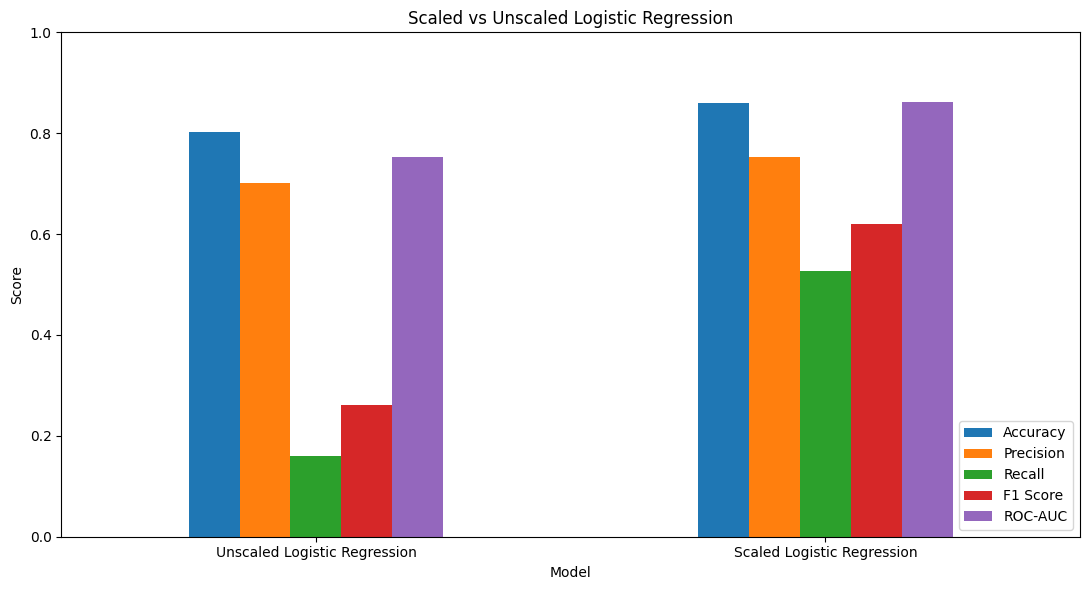

In [ ]:
plot_results = results.set_index(
    'Model'
)

plot_results.plot(
    kind='bar',
    figsize=(11, 6)
)

plt.ylabel('Score')
plt.title(
    'Scaled vs Unscaled Logistic Regression'
)

plt.ylim(0, 1)

plt.xticks(
    rotation=0
)

plt.legend(
    loc='lower right'
)

plt.tight_layout()
plt.show()

## Confusion Matrix

I also looked at the confusion matrix for each model. This shows the actual number of correct and incorrect classifications instead of summarizing performance into one score.

For this analysis, I am especially interested in false negatives. These are borrowers who actually defaulted but were predicted not to default. In a real credit risk setting, missing these borrowers could be more concerning than incorrectly identifying a non-defaulting borrower as higher risk.

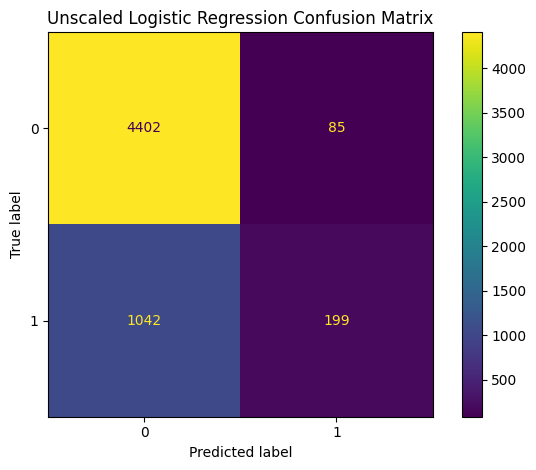

In [ ]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    unscaled_pred
)

plt.title(
    'Unscaled Logistic Regression Confusion Matrix'
)

plt.tight_layout()
plt.show()

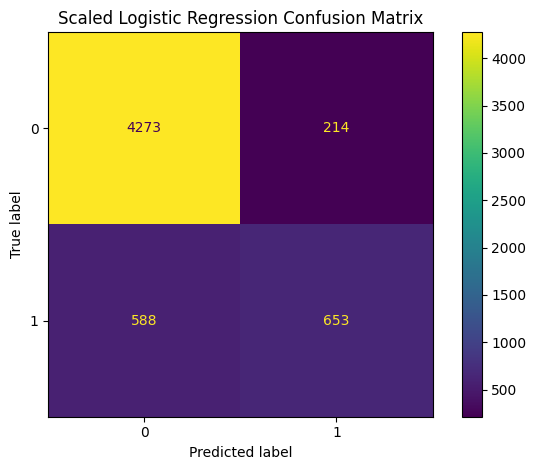

In [ ]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    scaled_pred
)

plt.title(
    'Scaled Logistic Regression Confusion Matrix'
)

plt.tight_layout()
plt.show()

## ROC Curve

The ROC curve shows how the true positive rate and false positive rate change across different classification thresholds.

A model with an ROC-AUC closer to 1 is better at separating borrowers who default from borrowers who do not. This gives me another way to compare the scaled and unscaled models without relying on only the default classification threshold.

<Figure size 800x600 with 0 Axes>

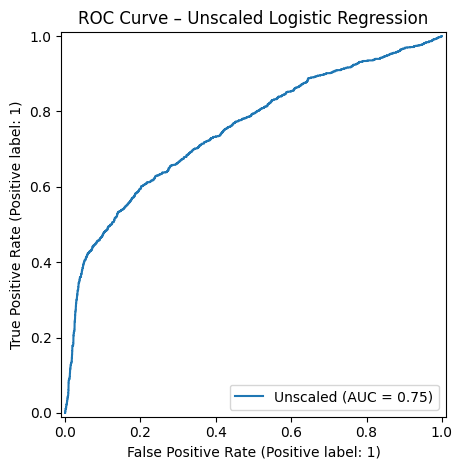

In [ ]:
plt.figure(figsize=(8, 6))

RocCurveDisplay.from_predictions(
    y_test,
    unscaled_prob,
    name='Unscaled'
)

plt.title(
    'ROC Curve – Unscaled Logistic Regression'
)

plt.tight_layout()
plt.show()

<Figure size 800x600 with 0 Axes>

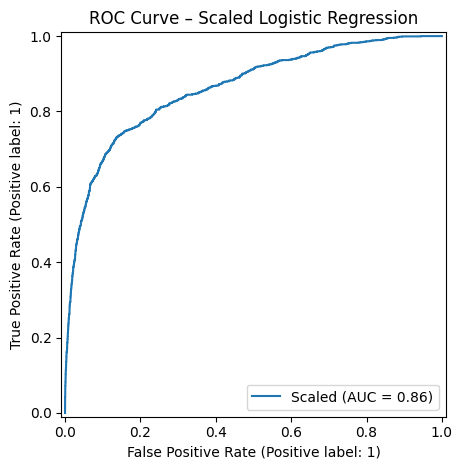

In [ ]:
plt.figure(figsize=(8, 6))

RocCurveDisplay.from_predictions(
    y_test,
    scaled_prob,
    name='Scaled'
)

plt.title(
    'ROC Curve – Scaled Logistic Regression'
)

plt.tight_layout()
plt.show()

## Logistic Regression Coefficients

I also looked at the coefficients from the scaled logistic regression model to get a better idea of which variables are associated with higher or lower predicted default risk.

A positive coefficient means that an increase in that predictor is associated with higher log-odds of default, while a negative coefficient is associated with lower log-odds of default.

Since the continuous variables were standardized, their coefficients are also easier to compare than they would be if the variables were left on very different scales.

In [ ]:
feature_names = (
    scaled_model
    .named_steps['preprocessor']
    .get_feature_names_out()
)

feature_names = [
    name.replace('continuous__', '')
        .replace('categorical__', '')
    for name in feature_names
]

coefficients = (
    scaled_model
    .named_steps['logistic']
    .coef_[0]
)

coefficient_df = pd.DataFrame({
    'Feature': feature_names,
    'Coefficient': coefficients
})

coefficient_df[
    'Absolute Coefficient'
] = coefficient_df[
    'Coefficient'
].abs()

coefficient_df = coefficient_df.sort_values(
    'Absolute Coefficient',
    ascending=False
)

display(
    coefficient_df.round(4)
)

,Feature,Coefficient,Absolute Coefficient
20,loan_grade_G,3.9191,3.9191
19,loan_grade_F,2.2679,2.2679
18,loan_grade_E,2.0905,2.0905
17,loan_grade_D,1.9553,1.9553
8,person_home_ownership_OWN,-1.9247,1.9247
5,loan_percent_income,1.4169,1.4169
14,loan_intent_VENTURE,-1.1363,1.1363
10,loan_intent_EDUCATION,-0.8944,0.8944
9,person_home_ownership_RENT,0.8152,0.8152
3,loan_amnt,-0.6499,0.6499


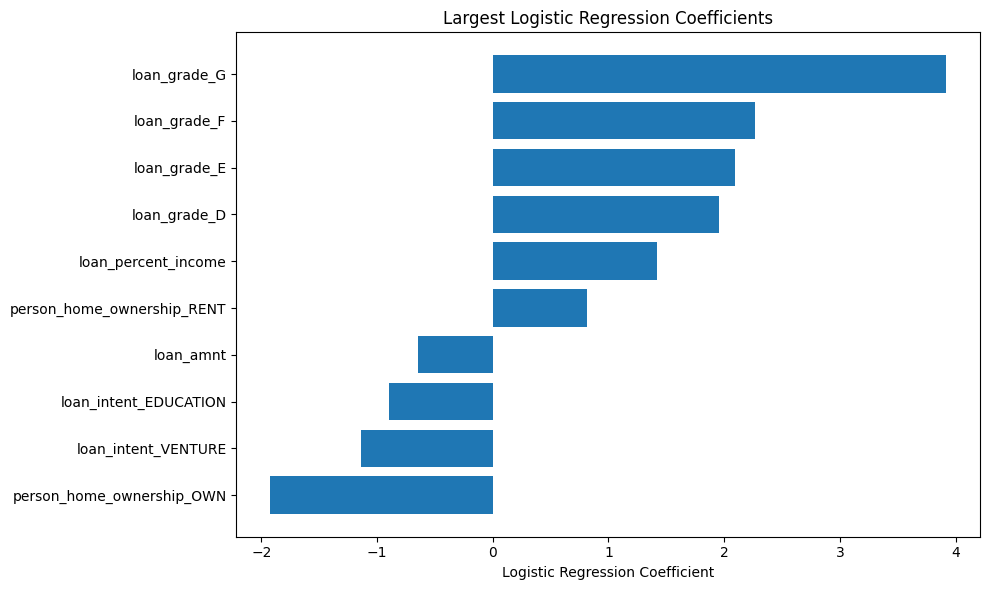

In [ ]:
top_coefficients = (
    coefficient_df
    .head(10)
    .sort_values('Coefficient')
)

plt.figure(figsize=(10, 6))

plt.barh(
    top_coefficients['Feature'],
    top_coefficients['Coefficient']
)

plt.xlabel(
    'Logistic Regression Coefficient'
)

plt.title(
    'Largest Logistic Regression Coefficients'
)

plt.tight_layout()
plt.show()

In [ ]:
metric_changes = pd.DataFrame({
    'Metric': [
        'Accuracy',
        'Precision',
        'Recall',
        'F1 Score',
        'ROC-AUC'
    ],
    'Unscaled': [
        unscaled_accuracy,
        unscaled_precision,
        unscaled_recall,
        unscaled_f1,
        unscaled_auc
    ],
    'Scaled': [
        scaled_accuracy,
        scaled_precision,
        scaled_recall,
        scaled_f1,
        scaled_auc
    ]
})

metric_changes[
    'Difference'
] = (
    metric_changes['Scaled'] -
    metric_changes['Unscaled']
)

display(
    metric_changes.round(4)
)

,Metric,Unscaled,Scaled,Difference
0,Accuracy,0.8032,0.8600,0.0567
1,Precision,0.7007,0.7532,0.0525
2,Recall,0.1604,0.5262,0.3658
3,F1 Score,0.2610,0.6195,0.3586
4,ROC-AUC,0.7520,0.8617,0.1097


In [ ]:
best_accuracy = results.loc[
    results['Accuracy'].idxmax(),
    'Model'
]

best_recall = results.loc[
    results['Recall'].idxmax(),
    'Model'
]

best_f1 = results.loc[
    results['F1 Score'].idxmax(),
    'Model'
]

best_auc = results.loc[
    results['ROC-AUC'].idxmax(),
    'Model'
]

scaled_cm = confusion_matrix(
    y_test,
    scaled_pred
)

tn, fp, fn, tp = scaled_cm.ravel()

print("WEEK 4 MODEL SUMMARY")
print("=" * 60)

print(
    "Highest Accuracy:",
    best_accuracy
)

print(
    "Highest Recall:",
    best_recall
)

print(
    "Highest F1 Score:",
    best_f1
)

print(
    "Highest ROC-AUC:",
    best_auc
)

print("\nScaled Model Confusion Matrix")
print("-" * 60)

print("True Negatives:", tn)
print("False Positives:", fp)
print("False Negatives:", fn)
print("True Positives:", tp)

print("\nLargest Absolute Coefficients")
print("-" * 60)

display(
    coefficient_df[
        ['Feature', 'Coefficient']
    ].head(10).round(4)
)

WEEK 4 MODEL SUMMARY
Highest Accuracy: Scaled Logistic Regression
Highest Recall: Scaled Logistic Regression
Highest F1 Score: Scaled Logistic Regression
Highest ROC-AUC: Scaled Logistic Regression

Scaled Model Confusion Matrix
------------------------------------------------------------
True Negatives: 4273
False Positives: 214
False Negatives: 588
True Positives: 653

Largest Absolute Coefficients
------------------------------------------------------------


,Feature,Coefficient
20,loan_grade_G,3.9191
19,loan_grade_F,2.2679
18,loan_grade_E,2.0905
17,loan_grade_D,1.9553
8,person_home_ownership_OWN,-1.9247
5,loan_percent_income,1.4169
14,loan_intent_VENTURE,-1.1363
10,loan_intent_EDUCATION,-0.8944
9,person_home_ownership_RENT,0.8152
3,loan_amnt,-0.6499


## Week 4 Conclusions

For Week 4, I used logistic regression to predict loan default and compared the model before and after feature scaling. The dataset was somewhat imbalanced, with 78.18% of borrowers in the non-default group and 21.82% in the default group. Because of this, I looked at several classification metrics instead of relying only on accuracy.

### Unscaled Logistic Regression

The unscaled logistic regression had an accuracy of 0.8032 and a ROC-AUC of 0.7520. At first, the accuracy seemed fairly good, but the other metrics showed that the model was not doing a good job of identifying borrowers who actually defaulted.

The model had a precision of 0.7007 but a recall of only 0.1604. This means that when the model predicted a default it was usually correct, but it missed most of the actual defaults. The F1 score was also fairly low at 0.2610.

### Feature Scaling

Feature scaling made a noticeable difference in the model's performance. After standardizing the continuous variables, accuracy increased from 0.8032 to 0.8600 and ROC-AUC increased from 0.7520 to 0.8617.

The biggest improvement was recall, which increased from 0.1604 to 0.5262. The F1 score also increased from 0.2610 to 0.6195. Precision improved from 0.7007 to 0.7532.

This was a much larger improvement than I expected. It shows that putting the continuous variables on similar scales helped the logistic regression model identify borrowers who defaulted.

### Confusion Matrix

The scaled model correctly identified 4,273 non-defaults and 653 defaults. It incorrectly classified 214 non-defaulting borrowers as defaults and missed 588 borrowers who actually defaulted.

The 588 false negatives are important because these borrowers actually defaulted but were classified as non-defaults. Even though scaling improved recall considerably, the model still missed almost half of the actual defaults. In a credit risk setting, this would be an important limitation to consider.

### Predictor Relationships

The coefficient results also showed some interesting relationships with default risk. Loan grades G, F, E, and D had some of the largest positive coefficients, with grade G having the largest coefficient at 3.9191. This suggests that borrowers in the lower loan grades were associated with higher predicted default risk compared with the reference grade.

`loan_percent_income` also had a relatively large positive coefficient of 1.4169, meaning that a larger loan relative to a borrower's income was associated with higher predicted default risk. Renting also had a positive coefficient, while owning a home had a large negative coefficient.

Some loan purposes, including venture and education, had negative coefficients relative to the reference category. Overall, loan grade and loan percent income appeared to be some of the more important factors in the model.

### Overall Conclusion

Overall, the scaled logistic regression performed much better than the unscaled model across every metric I evaluated. The improvement in recall was especially important because the goal of this model is to identify borrowers who default.

This week's results were different from Weeks 2 and 3, where changing the regression method did not improve performance very much. In Week 4, preprocessing the data through feature scaling had a clear effect on model performance.

The results also show why accuracy should not be used by itself when evaluating a classification model. The unscaled model had an accuracy above 80%, but its recall showed that it was missing most of the actual defaults. Looking at precision, recall, F1 score, ROC-AUC, and the confusion matrix gave me a much better understanding of how the model was actually performing.